In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import gseapy as gp

# Project paths
PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"

print("Project root:", PROJECT_ROOT.resolve())

# Load pseudobulk counts and metadata
counts = pd.read_csv(
    DATA_DIR / "beta_counts.csv",
    index_col=0
)

design = pd.read_csv(
    DATA_DIR / "beta_design.csv",
    index_col=0
)

# Keep ND and T2D only
design = design[design["Condition"].isin(["ND", "T2D"])].copy()

# Match donor order
counts = counts.loc[:, design.index]

print("\nCounts shape:", counts.shape)
print("Design shape:", design.shape)

print("\nDisease groups:")
print(design["Condition"].value_counts())

print("\nChemistry:")
print(design["Chemistry"].value_counts())

print(
    "\nDonor order matched:",
    list(counts.columns) == list(design.index)
)

Project root: E:\Project2_Pathway_SingleCell

Counts shape: (27739, 34)
Design shape: (34, 8)

Disease groups:
Condition
ND     17
T2D    17
Name: count, dtype: int64

Chemistry:
Chemistry
V3    23
V2    11
Name: count, dtype: int64

Donor order matched: True


In [2]:
# Reproduce gene filtering used in the audit notebook

# Keep genes with count >= 10 in at least 5 donors
keep = (counts >= 10).sum(axis=1) >= 5

filtered_counts = counts.loc[keep].copy()

print("Genes before filtering:", counts.shape[0])
print("Genes after filtering:", filtered_counts.shape[0])

# Library sizes
library_sizes = filtered_counts.sum(axis=0)

# CPM normalization
cpm = filtered_counts.divide(
    library_sizes,
    axis=1
) * 1_000_000

# Log2(CPM + 1)
log_cpm = np.log2(cpm + 1)

print("\nNormalized matrix shape:", log_cpm.shape)

print("\nCPM library sums:")
print(cpm.sum(axis=0).describe())

print(
    "\nDonor order still matched:",
    list(log_cpm.columns) == list(design.index)
)

Genes before filtering: 27739
Genes after filtering: 17408

Normalized matrix shape: (17408, 34)

CPM library sums:
count    3.400000e+01
mean     1.000000e+06
std      6.721242e-11
min      1.000000e+06
25%      1.000000e+06
50%      1.000000e+06
75%      1.000000e+06
max      1.000000e+06
dtype: float64

Donor order still matched: True


In [3]:
# Download pathway gene sets from Enrichr

kegg_sets = gp.get_library(
    name="KEGG_2021_Human",
    organism="human"
)

go_sets = gp.get_library(
    name="GO_Biological_Process_2023",
    organism="human"
)

print("KEGG pathways:", len(kegg_sets))
print("GO Biological Process pathways:", len(go_sets))

print("\nExample KEGG pathways:")
for i, name in enumerate(list(kegg_sets.keys())[:5], start=1):
    print(i, name)

print("\nExample GO pathways:")
for i, name in enumerate(list(go_sets.keys())[:5], start=1):
    print(i, name)

KEGG pathways: 320
GO Biological Process pathways: 5406

Example KEGG pathways:
1 ABC transporters
2 AGE-RAGE signaling pathway in diabetic complications
3 AMPK signaling pathway
4 Acute myeloid leukemia
5 Adherens junction

Example GO pathways:
1 'De Novo' AMP Biosynthetic Process (GO:0044208)
2 'De Novo' Post-Translational Protein Folding (GO:0051084)
3 2-Oxoglutarate Metabolic Process (GO:0006103)
4 3'-UTR-mediated mRNA Destabilization (GO:0061158)
5 3'-UTR-mediated mRNA Stabilization (GO:0070935)


In [4]:
# Filter KEGG pathways by overlap with the expressed gene universe

expressed_genes = set(log_cpm.index.astype(str))

filtered_kegg_sets = {}

for pathway, genes in kegg_sets.items():
    overlap = sorted(
        expressed_genes.intersection(
            {str(g).strip() for g in genes}
        )
    )

    # Keep pathways represented by 10-200 expressed genes
    if 10 <= len(overlap) <= 200:
        filtered_kegg_sets[pathway] = overlap

print("Original KEGG pathways:", len(kegg_sets))
print("Filtered KEGG pathways:", len(filtered_kegg_sets))

sizes = pd.Series({
    pathway: len(genes)
    for pathway, genes in filtered_kegg_sets.items()
})

print("\nGenes per retained pathway:")
print(sizes.describe())

print("\nExample retained pathways:")
for pathway, genes in list(filtered_kegg_sets.items())[:10]:
    print(f"{pathway}: {len(genes)} genes")

Original KEGG pathways: 320
Filtered KEGG pathways: 291

Genes per retained pathway:
count    291.000000
mean      66.529210
std       42.294799
min       10.000000
25%       31.500000
50%       57.000000
75%       97.500000
max      200.000000
dtype: float64

Example retained pathways:
ABC transporters: 35 genes
AGE-RAGE signaling pathway in diabetic complications: 78 genes
AMPK signaling pathway: 106 genes
Acute myeloid leukemia: 52 genes
Adherens junction: 62 genes
Adipocytokine signaling pathway: 57 genes
Adrenergic signaling in cardiomyocytes: 107 genes
African trypanosomiasis: 15 genes
Alanine, aspartate and glutamate metabolism: 30 genes
Alcoholism: 85 genes


In [5]:
# Build donor-level pathway activity scores
# Score = mean log-CPM of genes belonging to each KEGG pathway

pathway_scores = pd.DataFrame(
    index=design.index
)

for pathway, genes in filtered_kegg_sets.items():
    pathway_scores[pathway] = (
        log_cpm.loc[genes]
        .mean(axis=0)
        .reindex(design.index)
    )

print("Pathway score matrix shape:", pathway_scores.shape)

print("\nMissing values:")
print(pathway_scores.isna().sum().sum())

print("\nFirst 5 donors x first 5 pathways:")
print(pathway_scores.iloc[:5, :5])

print(
    "\nDonor order matched:",
    list(pathway_scores.index) == list(design.index)
)

C:\Users\strangers\AppData\Local\Temp\ipykernel_12872\2180003235.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pathway_scores[pathway] = (


Pathway score matrix shape: (34, 291)

Missing values:
0

First 5 donors x first 5 pathways:
          ABC transporters  \
Islet104          2.286201   
Islet107          2.108282   
Islet123          2.135863   
Islet29           2.168934   
Islet34           2.178691   

          AGE-RAGE signaling pathway in diabetic complications  \
Islet104                                           3.176170      
Islet107                                           2.942506      
Islet123                                           3.157630      
Islet29                                            3.183718      
Islet34                                            3.048508      

          AMPK signaling pathway  Acute myeloid leukemia  Adherens junction  
Islet104                3.830470                3.336016           4.137371  
Islet107                3.554117                3.123638           3.922509  
Islet123                3.721724                3.308053           4.016275  
Islet29          

In [6]:
pathway_scores.to_csv(
    "../results/tables/beta_KEGG_pathway_scores.csv"
)

print("Saved pathway scores.")

Saved pathway scores.


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

X_pathway = pathway_scores.copy()

y = (
    design["Condition"]
    .map({"ND": 0, "T2D": 1})
    .astype(int)
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l2",
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

pred = cross_val_predict(
    model,
    X_pathway,
    y,
    cv=cv,
    method="predict"
)

prob = cross_val_predict(
    model,
    X_pathway,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

print("Pathway model results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y, pred), 3))
print("Balanced accuracy:", round(balanced_accuracy_score(y, pred), 3))
print("ROC AUC:", round(roc_auc_score(y, prob), 3))

print("\nConfusion matrix:")
print(confusion_matrix(y, pred))

print("\nClassification report:")
print(
    classification_report(
        y,
        pred,
        target_names=["ND", "T2D"]
    )
)

Pathway model results
---------------------
Accuracy: 0.794
Balanced accuracy: 0.794
ROC AUC: 0.882

Confusion matrix:
[[14  3]
 [ 4 13]]

Classification report:
              precision    recall  f1-score   support

          ND       0.78      0.82      0.80        17
         T2D       0.81      0.76      0.79        17

    accuracy                           0.79        34
   macro avg       0.80      0.79      0.79        34
weighted avg       0.80      0.79      0.79        34



e:\Project2_Pathway_SingleCell\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
e:\Project2_Pathway_SingleCell\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
e:\Project2_Pathway_SingleCell\.venv

In [8]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

model_repeated = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=42
)

scores = cross_validate(
    model_repeated,
    X_pathway,
    y,
    cv=repeated_cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=False
)

print("Repeated 5-fold CV results")
print("--------------------------")

for metric in ["accuracy", "balanced_accuracy", "roc_auc"]:
    values = scores[f"test_{metric}"]

    print(
        f"{metric}: "
        f"mean={values.mean():.3f}, "
        f"std={values.std():.3f}, "
        f"min={values.min():.3f}, "
        f"max={values.max():.3f}"
    )

Repeated 5-fold CV results
--------------------------
accuracy: mean=0.798, std=0.125, min=0.333, max=1.000
balanced_accuracy: mean=0.798, std=0.128, min=0.333, max=1.000
roc_auc: mean=0.865, std=0.138, min=0.333, max=1.000


In [9]:
# Gene-level baseline model
# Donors x genes
X_gene = log_cpm.T.copy()

print("Gene-level feature matrix shape:", X_gene.shape)

gene_model = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

gene_scores = cross_validate(
    gene_model,
    X_gene,
    y,
    cv=repeated_cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=False
)

print("\nGene-level repeated 5-fold CV results")
print("------------------------------------")

for metric in ["accuracy", "balanced_accuracy", "roc_auc"]:
    values = gene_scores[f"test_{metric}"]

    print(
        f"{metric}: "
        f"mean={values.mean():.3f}, "
        f"std={values.std():.3f}, "
        f"min={values.min():.3f}, "
        f"max={values.max():.3f}"
    )

Gene-level feature matrix shape: (34, 17408)

Gene-level repeated 5-fold CV results
------------------------------------
accuracy: mean=0.881, std=0.087, min=0.667, max=1.000
balanced_accuracy: mean=0.879, std=0.090, min=0.667, max=1.000
roc_auc: mean=0.931, std=0.102, min=0.667, max=1.000


In [10]:
# Chemistry-only baseline
# Tests whether sequencing chemistry itself carries predictive signal

X_chemistry = pd.get_dummies(
    design[["Chemistry"]],
    drop_first=True,
    dtype=float
)

print("Chemistry features:")
print(X_chemistry.head())

chemistry_model = LogisticRegression(
    solver="liblinear",
    max_iter=5000,
    random_state=42
)

chemistry_scores = cross_validate(
    chemistry_model,
    X_chemistry,
    y,
    cv=repeated_cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=False
)

print("\nChemistry-only repeated 5-fold CV results")
print("-----------------------------------------")

for metric in ["accuracy", "balanced_accuracy", "roc_auc"]:
    values = chemistry_scores[f"test_{metric}"]

    print(
        f"{metric}: "
        f"mean={values.mean():.3f}, "
        f"std={values.std():.3f}, "
        f"min={values.min():.3f}, "
        f"max={values.max():.3f}"
    )

Chemistry features:
          Chemistry_V3
Islet104           1.0
Islet107           1.0
Islet123           1.0
Islet29            0.0
Islet34            0.0

Chemistry-only repeated 5-fold CV results
-----------------------------------------
accuracy: mean=0.556, std=0.162, min=0.143, max=0.833
balanced_accuracy: mean=0.556, std=0.155, min=0.125, max=0.833
roc_auc: mean=0.578, std=0.170, min=0.125, max=0.875


In [11]:
comparison = pd.DataFrame({
    "Model": [
        "Chemistry only",
        "Pathway features",
        "Gene features"
    ],
    "Balanced accuracy": [
        chemistry_scores["test_balanced_accuracy"].mean(),
        scores["test_balanced_accuracy"].mean(),
        gene_scores["test_balanced_accuracy"].mean()
    ],
    "ROC AUC": [
        chemistry_scores["test_roc_auc"].mean(),
        scores["test_roc_auc"].mean(),
        gene_scores["test_roc_auc"].mean()
    ]
})

comparison.to_csv(
    "../results/tables/model_comparison.csv",
    index=False
)

print(comparison)

              Model  Balanced accuracy   ROC AUC
0    Chemistry only           0.555833  0.577500
1  Pathway features           0.798333  0.865000
2     Gene features           0.878750  0.931111


In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(comparison))
width = 0.35

ax.bar(
    x - width/2,
    comparison["Balanced accuracy"],
    width,
    label="Balanced accuracy"
)

ax.bar(
    x + width/2,
    comparison["ROC AUC"],
    width,
    label="ROC AUC"
)

ax.set_xticks(x)
ax.set_xticklabels(
    comparison["Model"],
    rotation=15
)

ax.set_ylim(0, 1)
ax.set_ylabel("Cross-validated performance")
ax.set_title("Model comparison: T2D vs ND")
ax.legend()

plt.tight_layout()

plt.savefig(
    "../results/figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'plt' is not defined

In [13]:
import matplotlib.pyplot as plt

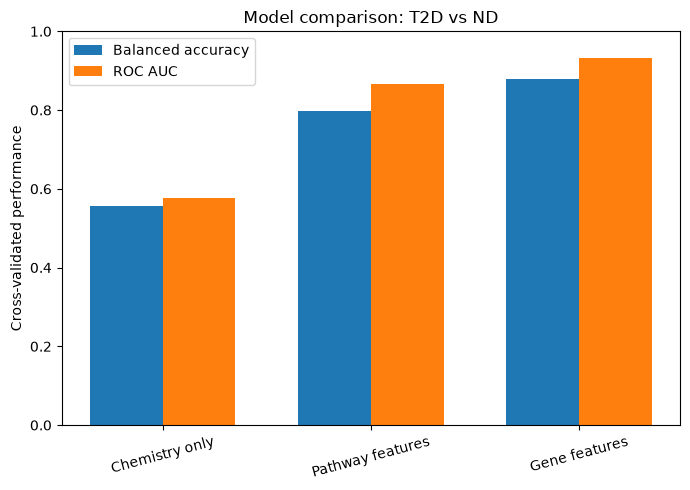

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(comparison))
width = 0.35

ax.bar(
    x - width/2,
    comparison["Balanced accuracy"],
    width,
    label="Balanced accuracy"
)

ax.bar(
    x + width/2,
    comparison["ROC AUC"],
    width,
    label="ROC AUC"
)

ax.set_xticks(x)
ax.set_xticklabels(
    comparison["Model"],
    rotation=15
)

ax.set_ylim(0, 1)
ax.set_ylabel("Cross-validated performance")
ax.set_title("Model comparison: T2D vs ND")
ax.legend()

plt.tight_layout()

plt.savefig(
    "../results/figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# Fit pathway model on all donors for interpretation

final_pathway_model = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

final_pathway_model.fit(X_pathway, y)

# Extract coefficients
coef = final_pathway_model.named_steps["logistic"].coef_[0]

pathway_importance = pd.DataFrame({
    "Pathway": X_pathway.columns,
    "Coefficient": coef
})

pathway_importance["Absolute coefficient"] = (
    pathway_importance["Coefficient"].abs()
)

pathway_importance = pathway_importance.sort_values(
    "Absolute coefficient",
    ascending=False
)

print("Top 15 pathways by absolute coefficient:")
print(
    pathway_importance[
        ["Pathway", "Coefficient"]
    ].head(15).to_string(index=False)
)

pathway_importance.to_csv(
    "../results/tables/pathway_model_coefficients.csv",
    index=False
)

Top 15 pathways by absolute coefficient:
                                 Pathway  Coefficient
Pentose and glucuronate interconversions    -0.302961
                   Arginine biosynthesis    -0.298791
     Central carbon metabolism in cancer    -0.274269
         Arginine and proline metabolism    -0.255132
              Hematopoietic cell lineage    -0.251350
   Carbohydrate digestion and absorption    -0.251273
               Selenocompound metabolism     0.241649
                Type I diabetes mellitus     0.234861
    Maturity onset diabetes of the young    -0.234485
                     Thiamine metabolism     0.226713
                      Retinol metabolism    -0.222750
                         Drug metabolism     0.218876
          Primary bile acid biosynthesis     0.216214
                              Amoebiasis    -0.216150
                Linoleic acid metabolism     0.210215


In [16]:
from sklearn.base import clone

# Collect pathway coefficients across repeated CV training folds

coef_records = []

for fold_id, (train_idx, test_idx) in enumerate(
    repeated_cv.split(X_pathway, y),
    start=1
):
    fold_model = clone(model_repeated)

    X_train = X_pathway.iloc[train_idx]
    y_train = y.iloc[train_idx]

    fold_model.fit(X_train, y_train)

    fold_coef = (
        fold_model
        .named_steps["logistic"]
        .coef_[0]
    )

    fold_df = pd.DataFrame({
        "Pathway": X_pathway.columns,
        "Coefficient": fold_coef,
        "Fold": fold_id
    })

    coef_records.append(fold_df)

cv_coefficients = pd.concat(
    coef_records,
    ignore_index=True
)

# Summarize stability
pathway_stability = (
    cv_coefficients
    .groupby("Pathway")["Coefficient"]
    .agg(
        mean_coefficient="mean",
        sd_coefficient="std",
        mean_absolute_coefficient=lambda x: np.mean(np.abs(x)),
        positive_fraction=lambda x: np.mean(x > 0),
        negative_fraction=lambda x: np.mean(x < 0)
    )
    .reset_index()
)

# Sign consistency = proportion of folds agreeing on dominant direction
pathway_stability["sign_consistency"] = (
    pathway_stability[
        ["positive_fraction", "negative_fraction"]
    ].max(axis=1)
)

pathway_stability = pathway_stability.sort_values(
    ["sign_consistency", "mean_absolute_coefficient"],
    ascending=[False, False]
)

print("Top 20 stable pathway predictors:")
print(
    pathway_stability[
        [
            "Pathway",
            "mean_coefficient",
            "sd_coefficient",
            "mean_absolute_coefficient",
            "sign_consistency"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

pathway_stability.to_csv(
    "../results/tables/pathway_coefficient_stability.csv",
    index=False
)

Top 20 stable pathway predictors:
                                                      Pathway  mean_coefficient  sd_coefficient  mean_absolute_coefficient  sign_consistency
                                        Arginine biosynthesis         -0.255794        0.073855                   0.255794               1.0
                     Pentose and glucuronate interconversions         -0.245119        0.043359                   0.245119               1.0
                          Central carbon metabolism in cancer         -0.224328        0.039193                   0.224328               1.0
                        Carbohydrate digestion and absorption         -0.219624        0.026885                   0.219624               1.0
                         Maturity onset diabetes of the young         -0.212705        0.042013                   0.212705               1.0
                                     Type I diabetes mellitus          0.203852        0.032885                   0.2038

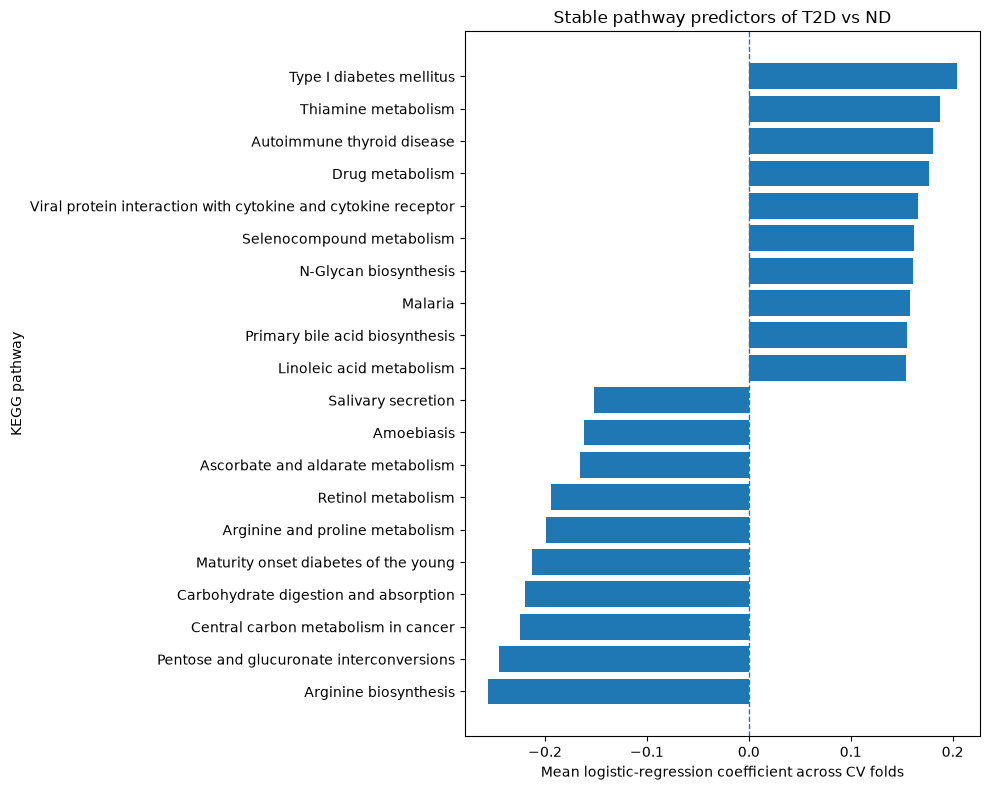

In [17]:
# Plot the most stable pathway predictors

top_stable = (
    pathway_stability
    .sort_values(
        "mean_absolute_coefficient",
        ascending=False
    )
    .head(20)
    .sort_values("mean_coefficient")
)

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    top_stable["Pathway"],
    top_stable["mean_coefficient"]
)

ax.axvline(0, linestyle="--", linewidth=1)

ax.set_xlabel("Mean logistic-regression coefficient across CV folds")
ax.set_ylabel("KEGG pathway")
ax.set_title("Stable pathway predictors of T2D vs ND")

plt.tight_layout()

plt.savefig(
    "../results/figures/stable_pathway_predictors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# Add chemistry as an explicit covariate

chemistry_numeric = pd.get_dummies(
    design[["Chemistry"]],
    drop_first=True,
    dtype=float
)

# Pathway + chemistry
X_pathway_chem = pd.concat(
    [X_pathway, chemistry_numeric],
    axis=1
)

# Gene + chemistry
X_gene_chem = pd.concat(
    [X_gene, chemistry_numeric],
    axis=1
)

pathway_chem_scores = cross_validate(
    model_repeated,
    X_pathway_chem,
    y,
    cv=repeated_cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=False
)

gene_chem_scores = cross_validate(
    gene_model,
    X_gene_chem,
    y,
    cv=repeated_cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=False
)

print("Pathway + chemistry")
print("-------------------")
for metric in ["accuracy", "balanced_accuracy", "roc_auc"]:
    values = pathway_chem_scores[f"test_{metric}"]
    print(
        f"{metric}: "
        f"mean={values.mean():.3f}, "
        f"std={values.std():.3f}"
    )

print("\nGene + chemistry")
print("----------------")
for metric in ["accuracy", "balanced_accuracy", "roc_auc"]:
    values = gene_chem_scores[f"test_{metric}"]
    print(
        f"{metric}: "
        f"mean={values.mean():.3f}, "
        f"std={values.std():.3f}"
    )

Pathway + chemistry
-------------------
accuracy: mean=0.798, std=0.125
balanced_accuracy: mean=0.798, std=0.128
roc_auc: mean=0.865, std=0.138

Gene + chemistry
----------------
accuracy: mean=0.881, std=0.087
balanced_accuracy: mean=0.879, std=0.090
roc_auc: mean=0.931, std=0.102


In [19]:
final_comparison = pd.DataFrame({
    "Model": [
        "Chemistry only",
        "Pathway features",
        "Pathway + chemistry",
        "Gene features",
        "Gene + chemistry"
    ],
    "Balanced accuracy": [
        chemistry_scores["test_balanced_accuracy"].mean(),
        scores["test_balanced_accuracy"].mean(),
        pathway_chem_scores["test_balanced_accuracy"].mean(),
        gene_scores["test_balanced_accuracy"].mean(),
        gene_chem_scores["test_balanced_accuracy"].mean()
    ],
    "ROC AUC": [
        chemistry_scores["test_roc_auc"].mean(),
        scores["test_roc_auc"].mean(),
        pathway_chem_scores["test_roc_auc"].mean(),
        gene_scores["test_roc_auc"].mean(),
        gene_chem_scores["test_roc_auc"].mean()
    ]
})

final_comparison.to_csv(
    "../results/tables/final_model_comparison.csv",
    index=False
)

print(final_comparison)

                 Model  Balanced accuracy   ROC AUC
0       Chemistry only           0.555833  0.577500
1     Pathway features           0.798333  0.865000
2  Pathway + chemistry           0.798333  0.865000
3        Gene features           0.878750  0.931111
4     Gene + chemistry           0.878750  0.931111


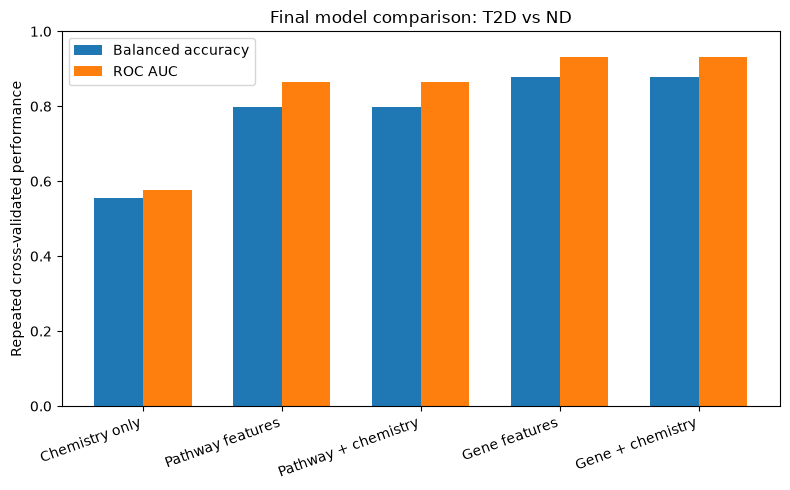

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(final_comparison))
width = 0.35

ax.bar(
    x - width/2,
    final_comparison["Balanced accuracy"],
    width,
    label="Balanced accuracy"
)

ax.bar(
    x + width/2,
    final_comparison["ROC AUC"],
    width,
    label="ROC AUC"
)

ax.set_xticks(x)
ax.set_xticklabels(
    final_comparison["Model"],
    rotation=20,
    ha="right"
)

ax.set_ylim(0, 1)
ax.set_ylabel("Repeated cross-validated performance")
ax.set_title("Final model comparison: T2D vs ND")
ax.legend()

plt.tight_layout()

plt.savefig(
    "../results/figures/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()